### Imports and Configuration

In [21]:
import sys
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from tensorflow import keras
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)

CURRENT_DIR = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        path for path in (CURRENT_DIR, *CURRENT_DIR.parents)
        if (path / "config" / "settings.py").is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise RuntimeError("Could not find config/settings.py.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config import settings

keras.utils.set_random_seed(settings.RANDOM_STATE)

MODEL_PATH = settings.CLASSIFICATION_MODELS_DIR / "inceptionv3_final.keras"
CLASS_MAPPING_PATH = (
    settings.CLASSIFICATION_MODELS_DIR / "inceptionv3_class_mapping.json"
)
TEST_MANIFEST_PATH = settings.TEST_MANIFEST_PATH

REPORTS_DIR = settings.REPORTS_DIR
FIGURES_DIR = settings.FIGURES_DIR
METRICS_DIR = settings.METRICS_DIR

for directory in [REPORTS_DIR, FIGURES_DIR, METRICS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project:", settings.PROJECT_NAME)
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("Model path:", MODEL_PATH)
print("Test manifest:", TEST_MANIFEST_PATH)

Project: BrainScan_AI
TensorFlow: 2.21.0
GPU devices: []
Model path: /home/moali/projects/brainscan_ai/models/classification/inceptionv3_final.keras
Test manifest: /home/moali/projects/brainscan_ai/data/splits/test.csv


### 2 -  Load the trained model and class mapping

In [22]:
if not MODEL_PATH.is_file():
    raise FileNotFoundError(
        f"Final model not found: {MODEL_PATH}. "
        "Complete Notebook 05 first."
    )

if not CLASS_MAPPING_PATH.is_file():
    raise FileNotFoundError(
        f"Class mapping not found: {CLASS_MAPPING_PATH}."
    )

if not TEST_MANIFEST_PATH.is_file():
    raise FileNotFoundError(
        f"Test manifest not found: {TEST_MANIFEST_PATH}. "
        "Run Notebook 02 and verify the test split."
    )

model = keras.models.load_model(MODEL_PATH, compile=False)

with open(CLASS_MAPPING_PATH, encoding="utf-8") as file:
    class_config = json.load(file)

CLASS_NAMES = [str(name) for name in class_config["classes"]]
LABEL_TO_ID = {
    str(label): int(index)
    for label, index in class_config["label_to_id"].items()
}
NUM_CLASSES = len(CLASS_NAMES)

IMAGE_HEIGHT = model.input_shape[1]
IMAGE_WIDTH = model.input_shape[2]
IMAGE_CHANNELS = model.input_shape[3]
INPUT_SHAPE = (IMAGE_HEIGHT, IMAGE_WIDTH, IMAGE_CHANNELS)

if model.output_shape[-1] != NUM_CLASSES:
    raise ValueError(
        f"Model outputs {model.output_shape[-1]} classes, "
        f"but the class mapping defines {NUM_CLASSES}."
    )

print("Model:", model.name)
print("Input shape:", INPUT_SHAPE)
print("Classes:", CLASS_NAMES)
print("Number of classes:", NUM_CLASSES)

Model: BrainScan_InceptionV3
Input shape: (299, 299, 3)
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Number of classes: 4


In [23]:
!nvidia-smi

Tue Oct 27 09:22:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.99.02              Driver Version: 595.99.02      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX 2000 Ada Gene...    Off |   00000000:01:00.0 Off |                  N/A |
| N/A   51C    P8              1W /   35W |      17MiB /   8188MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### 3 — Load and validate the test manifest

In [24]:
test_df = pd.read_csv(TEST_MANIFEST_PATH)

IMAGE_PATH_COL = "image_path"
LABEL_COL = "label"

required_columns = {IMAGE_PATH_COL, LABEL_COL}
missing_columns = required_columns - set(test_df.columns)

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}. "
        f"Available columns: {test_df.columns.tolist()}"
    )

if test_df.empty:
    raise ValueError("The test manifest is empty.")

if test_df[IMAGE_PATH_COL].isna().any() or test_df[LABEL_COL].isna().any():
    raise ValueError("The test manifest contains missing paths or labels.")

test_df["label_name"] = test_df[LABEL_COL].astype(str)

unknown_labels = set(test_df["label_name"]) - set(LABEL_TO_ID)

if unknown_labels:
    raise ValueError(f"Unknown test labels: {unknown_labels}")

test_df["label_id"] = test_df["label_name"].map(LABEL_TO_ID).astype("int32")


def resolve_image_path(value):
    path = Path(str(value)).expanduser()

    if not path.is_absolute():
        path = PROJECT_ROOT / path

    return path.resolve()


test_df["resolved_image_path"] = test_df[IMAGE_PATH_COL].map(
    resolve_image_path
)

missing_files = [
    str(path)
    for path in test_df["resolved_image_path"]
    if not path.is_file()
]

if missing_files:
    raise FileNotFoundError(
        f"{len(missing_files)} test images are missing. "
        f"Examples: {missing_files[:5]}"
    )

print("Test images:", len(test_df))
print("\nTest class distribution:")
display(
    test_df["label_name"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
    .rename("count")
    .to_frame()
)

Test images: 1054

Test class distribution:


,count
label_name,
glioma,243
meningioma,247
notumor,300
pituitary,264


### 4 — Create the test dataset

In [25]:
AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = settings.BATCH_SIZE


def load_test_image(image_path, label):
    image_bytes = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False,
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMAGE_HEIGHT, IMAGE_WIDTH],
        antialias=True,
    )

    image = tf.cast(image, tf.float32)

    image = keras.applications.inception_v3.preprocess_input(image)

    return image, label


test_ds = tf.data.Dataset.from_tensor_slices(
    (
        test_df["resolved_image_path"].astype(str).to_numpy(),
        test_df["label_id"].to_numpy(dtype=np.int32),
    )
)

test_ds = test_ds.map(
    load_test_image,
    num_parallel_calls=AUTOTUNE,
)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

print("Test dataset ready.")
print("Expected input:", model.input_shape)
print("Actual batch shape:", next(iter(test_ds))[0].shape)

Test dataset ready.
Expected input: (None, 299, 299, 3)
Actual batch shape: (32, 299, 299, 3)


### 5 — Generate predictions

In [26]:
y_true = test_df["label_id"].to_numpy()

start_time = time.perf_counter()

probabilities = model.predict(test_ds, verbose=1)

total_inference_time = time.perf_counter() - start_time

y_pred = np.argmax(probabilities, axis=1)
confidence = np.max(probabilities, axis=1)

assert len(y_true) == len(y_pred), "Prediction count mismatch."

print("Predictions generated:", len(y_pred))
print(f"Total prediction time: {total_inference_time:.3f} seconds")
print(f"Average time per image: {total_inference_time / len(y_pred):.6f} seconds")

33/33 ━━━━━━━━━━━━━━━━━━━━ 31s 895ms/step
Predictions generated: 1054
Total prediction time: 31.441 seconds
Average time per image: 0.029830 seconds


### 6 — Calculate classification metrics

In [28]:
accuracy = accuracy_score(y_true, y_pred)

macro_precision, macro_recall, macro_f1, _ = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        average="macro",
        zero_division=0,
    )
)

weighted_precision, weighted_recall, weighted_f1, _ = (
    precision_recall_fscore_support(
        y_true, 
        y_pred, 
        labels=np.arange(NUM_CLASSES),
        average="weighted",
        zero_division=0,
    )
)

metrics = {
    "test_samples": int(len(y_true)),
    "accuracy": float(accuracy),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "macro_f1": float(macro_f1),
    "weighted_precision": float(weighted_precision),
    "weighted_recall": float(weighted_recall),
    "weighted_f1": float(weighted_f1),
    "total_inference_seconds": float(total_inference_time),
    "average_inference_seconds_per_image": float(
        total_inference_time / len(y_true)
    ),
}

display(
    pd.DataFrame(
        [{"Metric": key, "Value": value} for key, value in metrics.items()]
    )
)

,Metric,Value
0,test_samples,1054.000000
1,accuracy,0.910816
2,macro_precision,0.906608
3,macro_recall,0.905856
4,macro_f1,0.905461
5,weighted_precision,0.909238
6,weighted_recall,0.910816
7,weighted_f1,0.909282
8,total_inference_seconds,31.440737
9,average_inference_seconds_per_image,0.029830


### 7 — Per-class classification report

In [29]:
report_dict = classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)

report_df = pd.DataFrame(report_dict).T

display(report_df.round(4))

REPORT_PATH = METRICS_DIR / "inceptionv3_classification_report.csv"
report_df.to_csv(REPORT_PATH, index=True)

print("Classification report saved to:", REPORT_PATH)


,precision,recall,f1-score,support
glioma,0.8848,0.8848,0.8848,243.0000
meningioma,0.8655,0.7814,0.8213,247.0000
notumor,0.9515,0.9800,0.9655,300.0000
pituitary,0.9247,0.9773,0.9503,264.0000
accuracy,0.9108,0.9108,0.9108,0.9108
macro avg,0.9066,0.9059,0.9055,1054.0000
weighted avg,0.9092,0.9108,0.9093,1054.0000


Classification report saved to: /home/moali/projects/brainscan_ai/reports/metrics/inceptionv3_classification_report.csv


### 8 — Plot the confusion matrix

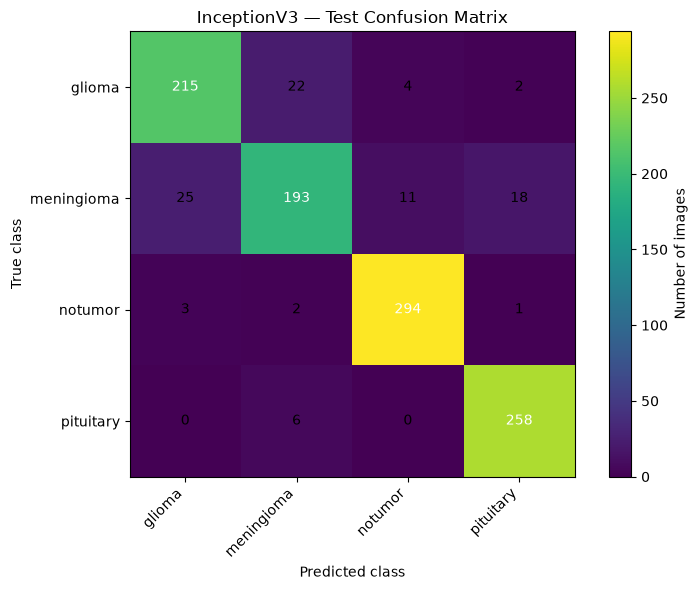

Confusion matrix saved to: /home/moali/projects/brainscan_ai/reports/figures/inceptionv3_confusion_matrix.png


In [31]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
)

fig, ax = plt.subplots(figsize=(max(8, NUM_CLASSES * 1.2), max(6, NUM_CLASSES)))

image = ax.imshow(cm, interpolation="nearest")
fig.colorbar(image, ax=ax, label="Number of images")

ax.set(
    xticks=np.arange(NUM_CLASSES),
    yticks=np.arange(NUM_CLASSES),
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    xlabel="Predicted class",
    ylabel="True class",
    title="InceptionV3 — Test Confusion Matrix",
)

plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

threshold = cm.max() / 2 if cm.size and cm.max() > 0 else 0

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black",
        )

plt.tight_layout()

CONFUSION_MATRIX_PATH = FIGURES_DIR / "inceptionv3_confusion_matrix.png"
plt.savefig(CONFUSION_MATRIX_PATH, dpi=150, bbox_inches="tight")
plt.show()

print("Confusion matrix saved to:", CONFUSION_MATRIX_PATH)

### 9 — Save predictions and inspect mistakes

In [32]:
predictions_df = test_df.copy()

predictions_df["true_class"] = [
    CLASS_NAMES[index] for index in y_true
]
predictions_df["predicted_class"] = [
    CLASS_NAMES[index] for index in y_pred
]
predictions_df["confidence"] = confidence
predictions_df["correct"] = y_true == y_pred

PREDICTIONS_PATH = METRICS_DIR / "inceptionv3_test_predictions.csv"
predictions_df.to_csv(PREDICTIONS_PATH, index=False)

errors_df = predictions_df.loc[~predictions_df["correct"]].copy()
errors_df = errors_df.sort_values("confidence", ascending=False)

ERRORS_PATH = METRICS_DIR / "inceptionv3_misclassified_images.csv"
errors_df.to_csv(ERRORS_PATH, index=False)

print(f"Correct predictions: {(y_true == y_pred).sum()}")
print(f"Incorrect predictions: {(y_true != y_pred).sum()}")
print(f"Test accuracy: {accuracy:.4f}")

display(
    errors_df[
        ["resolved_image_path", "true_class", "predicted_class", "confidence"]
    ].head(20)
)

print("All predictions saved to:", PREDICTIONS_PATH)
print("Misclassified cases saved to:", ERRORS_PATH)

Correct predictions: 960
Incorrect predictions: 94
Test accuracy: 0.9108


,resolved_image_path,true_class,predicted_class,confidence
37,/home/moali/projects/brainscan_ai/data/raw/men...,meningioma,notumor,0.997883
515,/home/moali/projects/brainscan_ai/data/raw/men...,meningioma,pituitary,0.989604
787,/home/moali/projects/brainscan_ai/data/raw/men...,meningioma,notumor,0.985373
619,/home/moali/projects/brainscan_ai/data/raw/men...,meningioma,pituitary,0.978112
86,/home/moali/projects/brainscan_ai/data/raw/men...,meningioma,pituitary,0.944607
326,/home/moali/projects/brainscan_ai/data/raw/men...,meningioma,pituitary,0.923444
830,/home/moali/projects/brainscan_ai/data/raw/men...,meningioma,notumor,0.914598
162,/home/moali/projects/brainscan_ai/data/raw/gli...,glioma,meningioma,0.902795
770,/home/moali/projects/brainscan_ai/data/raw/men...,meningioma,pituitary,0.897602
506,/home/moali/projects/brainscan_ai/data/raw/men...,meningioma,pituitary,0.887684


All predictions saved to: /home/moali/projects/brainscan_ai/reports/metrics/inceptionv3_test_predictions.csv
Misclassified cases saved to: /home/moali/projects/brainscan_ai/reports/metrics/inceptionv3_misclassified_images.csv


### 10 — Visualize misclassified images

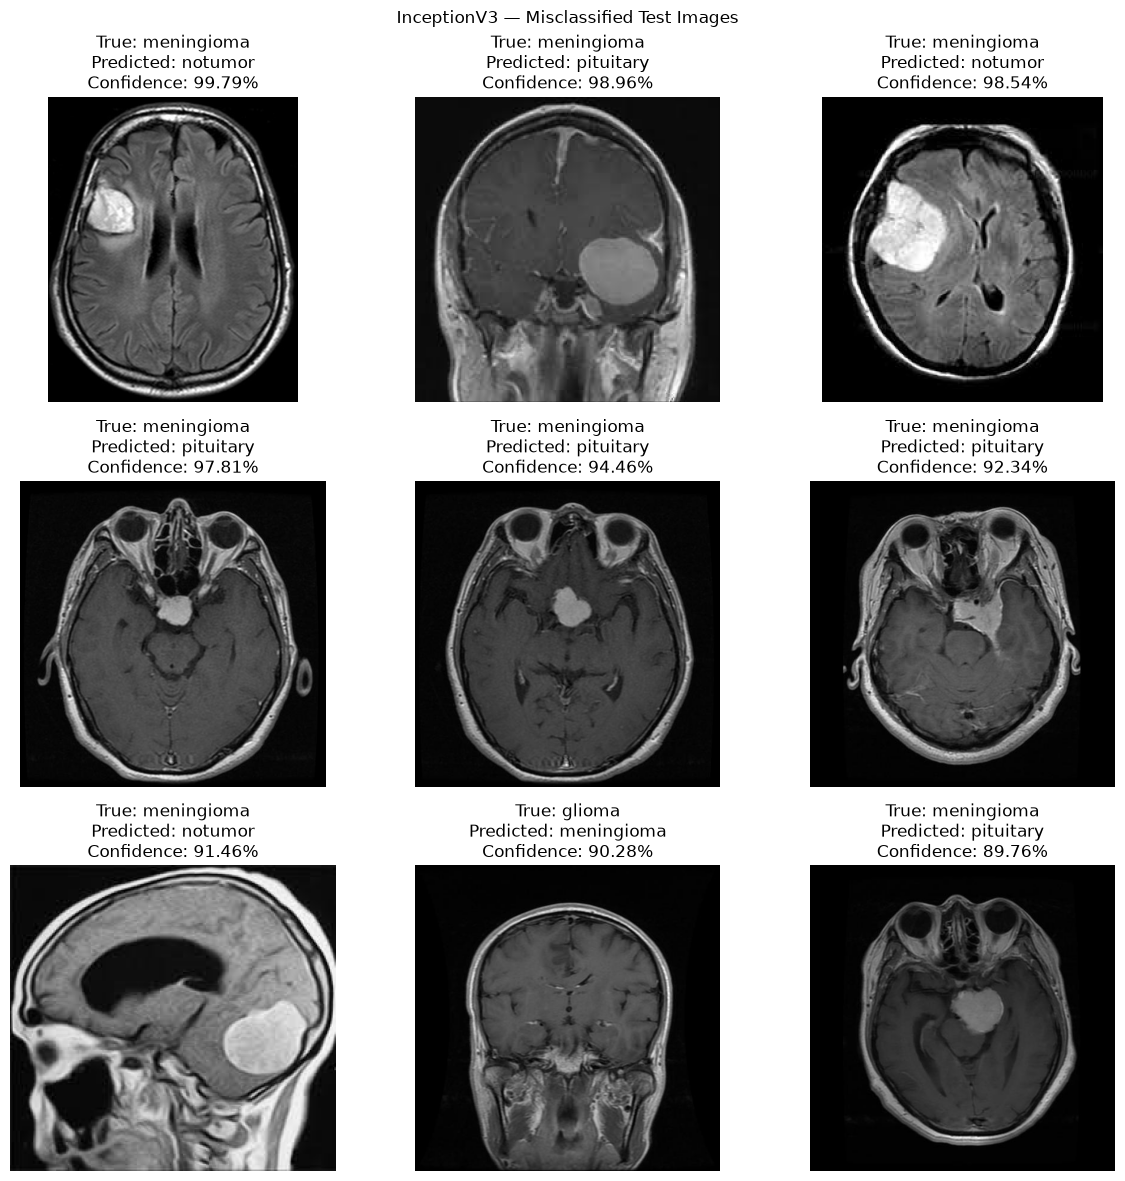

Error examples saved to: /home/moali/projects/brainscan_ai/reports/figures/inceptionv3_misclassified_examples.png


In [33]:
from PIL import Image

num_examples = min(9, len(errors_df))

if num_examples == 0:
    print("No misclassified images found in this test run.")
else:
    fig, axes = plt.subplots(3, 3, figsize=(12, 12))
    axes = axes.flatten()

    for ax in axes:
        ax.axis("off")

    for i, (_, row) in enumerate(errors_df.head(num_examples).iterrows()):
        with Image.open(row["resolved_image_path"]) as image:
            axes[i].imshow(image.convert("RGB"))

        axes[i].set_title(
            f"True: {row['true_class']}\n"
            f"Predicted: {row['predicted_class']}\n"
            f"Confidence: {row['confidence']:.2%}"
        )
        axes[i].axis("off")

    plt.suptitle("InceptionV3 — Misclassified Test Images")
    plt.tight_layout()

    ERROR_FIGURE_PATH = FIGURES_DIR / "inceptionv3_misclassified_examples.png"
    plt.savefig(ERROR_FIGURE_PATH, dpi=150, bbox_inches="tight")
    plt.show()

    print("Error examples saved to:", ERROR_FIGURE_PATH)

### 11 — Export the final evaluation summary

In [34]:
METRICS_PATH = METRICS_DIR / "inceptionv3_test_metrics.json"

evaluation_summary = {
    "model": "InceptionV3",
    "evaluation_split": "test",
    "test_samples": int(len(test_df)),
    "input_shape": list(INPUT_SHAPE),
    "class_names": CLASS_NAMES,
    "metrics": metrics,
    "confusion_matrix": cm.tolist(),
    "limitations": [
        "Results depend on the quality and representativeness of the dataset.",
        "Prediction confidence is not a calibrated measure of clinical certainty.",
        "This evaluation does not establish clinical safety or diagnostic readiness.",
    ],
}

with open(METRICS_PATH, "w", encoding="utf-8") as file:
    json.dump(evaluation_summary, file, indent=4)

print("Evaluation summary saved to:", METRICS_PATH)
print("\nEvaluation completed.")

Evaluation summary saved to: /home/moali/projects/brainscan_ai/reports/metrics/inceptionv3_test_metrics.json

Evaluation completed.
